# 光電離生成レートの軸方向・径方向プロファイル

一様な乾燥 N₂/O₂ 中にガウス型の発光源を与え、実装済みの3項Helmholtzソルバを単独で検証します。ストリーマの時間発展や保存済みの計算結果は不要です。

添付図の出典に合わせ、領域の半径・軸長は2 mm、ガウス幅は0.1 mm、中心は $(r,z)=(0,1\,\mathrm{mm})$、酸素分圧は150 Torrとします。図4では2項近似が使われています。ここでは実装の3項近似と境界条件（対称軸、下端ゼロ、外周・上端Robin）を使います。

参照曲線は、球対称ガウス源に対する **Zheleznyakの自由空間積分** と **同じ3項近似核の自由空間積分** です。前者と後者の差が核の近似誤差、後者と格子解の差が有限境界と離散化を合わせた影響です。

[Bourdon et al. (2007), 式 (1)–(3)、(7)–(8)、(31)、表2、図4](https://doi.org/10.1088/0963-0252/16/3/026)

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import exprel, roots_legendre

# Notebook、リポジトリ直下、その親から実行できるようにする。
repo = next(
    (candidate for parent in (Path.cwd(), *Path.cwd().parents)
     for candidate in (parent, parent / "pyaxistreamer-master")
     if (candidate / "streamer_drift_diffusion").is_dir()),
    None,
)
if repo is None:
    raise FileNotFoundError("PyAxiStreamerのリポジトリ内からNotebookを起動してください。")
sys.path.insert(0, str(repo))

from streamer_drift_diffusion import SimulationConfig
from streamer_drift_diffusion.grid import CylindricalGrid
from streamer_drift_diffusion.photoionization import PhotoionizationSolver

DOMAIN_M = 2e-3                      # 半径と軸長 [m]
CELLS = 201                          # 各方向のセル数
SIGMA_M = 1e-4                       # exp(-d²/σ²) の幅 [m]
Z0_M = DOMAIN_M / 2
OXYGEN_TORR = 150.
PHOTON_PEAK = 3.5e28                 # 消光補正後の発光源の最大値 [m^-3 s^-1]
RATE_LIMITS_CM = (1e17, 1e23)         # 表示範囲 [cm^-3 s^-1]。Noneなら全範囲

## ガウス源に対する格子解

発光源を $I(r,z)=I_0\exp[-(r^2+(z-z_0)^2)/\sigma^2]$ とします。ソルバの入力は電子衝突電離源 $S_i$ なので、実装と同じ発光効率と消光係数で $I$ を割って渡します。領域全体を気体とし、セル中心の $r$ と $z$ を使用します。

In [2]:
config = SimulationConfig(
    nr=CELLS, nz=CELLS, delta=DOMAIN_M / CELLS,
    oxygen_fraction=OXYGEN_TORR / 760., nitrogen_fraction=1. - OXYGEN_TORR / 760.,
    photoionization_efficiency=0.06,
)
grid = CylindricalGrid(config)
r_m, z_m = grid.rh, grid.zh
distance_m = np.hypot(r_m[:, None], z_m[None, :] - Z0_M)
photon_yield = config.photoionization_efficiency * 4000. / (101325. + 4000.)
impact = PHOTON_PEAK / photon_yield * np.exp(-(distance_m / SIGMA_M)**2)

solver = PhotoionizationSolver(grid, np.ones(grid.shape, dtype=bool), config)
try:
    rate, components = solver.solve(impact, return_components=True)
finally:
    solver.close()
np.testing.assert_allclose(components.sum(axis=0), rate, rtol=1e-14)

iz = int(np.argmin(np.abs(z_m - Z0_M)))
print(f"Grid spacing: {config.delta * 1e6:.3f} µm")
print(f"Axial cut at r = {r_m[0] * 1e6:.3f} µm")
print(f"Radial cut at z = {z_m[iz] * 1e3:.3f} mm")

Grid spacing: 9.950 µm
Axial cut at r = 4.975 µm
Radial cut at z = 1.000 mm


## 自由空間積分による参照解

観測点から発光中心までの距離を $d$、光の飛行距離を $R$ とします。観測点の周りの球面でガウス発光源を解析的に平均すると、どちらの核も $S_{\mathrm{ph}}(d)=\int_0^\infty \overline I(d,R)\,g(R)\,\mathrm dR$ という1次元積分になります。

$g(R)$ には原論文の吸収関数（式3）と3項近似（式9、表2）を使います。発光中心から十分離れたガウスの裾を除いて積分し、求積点数を倍にして参照値の収束を確認します。

In [3]:
def free_space_rates(distance, quadrature_order):
    """球対称ガウス源に対する自由空間の光電離源を求める。

    Parameters
    ----------
    distance : ndarray, shape (n,)
        発光中心から各観測点までの距離 [m]。
    quadrature_order : int
        Gauss–Legendre求積の点数。

    Returns
    -------
    ndarray, shape (2, n)
        Zheleznyak積分、3項近似核の積分の順 [m^-3 s^-1]。

    Examples
    --------
    >>> free_space_rates(np.array([0.]), 128).shape
    (2, 1)
    """
    nodes, weights = roots_legendre(quadrature_order)
    d = distance[:, None]
    lower = np.maximum(0., d - 10*SIGMA_M)
    upper = d + 10*SIGMA_M
    half_width = (upper - lower) / 2
    flight = (upper + lower) / 2 + half_width * nodes
    # exprel(x) = expm1(x)/x。d=0でも球面平均の極限をそのまま評価できる。
    angular_average = (PHOTON_PEAK * np.exp(-((d - flight)/SIGMA_M)**2)
                       * exprel(-4 * d * flight / SIGMA_M**2))
    measure = angular_average * half_width * weights

    a, b = 100 * OXYGEN_TORR * np.array([0.035, 2.])
    absorption = (b-a) * np.exp(-a*flight) * exprel(-(b-a)*flight) / np.log(b/a)
    # Bourdon 表2の係数。ソルバの変数を参照せず、cmからmへ換算する。
    pressure_factor = 100 * OXYGEN_TORR
    fit = flight * pressure_factor**2 * sum(
        amplitude * np.exp(-decay * pressure_factor * flight)
        for amplitude, decay in ((1.986e-4, 0.0553), (0.0051, 0.1460), (0.4886, 0.89))
    )
    return np.array([np.sum(kernel * measure, axis=1) for kernel in (absorption, fit)])


cuts = (
    ("Axial", "z", z_m, distance_m[0, :], rate[0, :], components[:, 0, :]),
    ("Radial", "r", r_m, distance_m[:, iz], rate[:, iz], components[:, :, iz]),
)
references = {}
for name, _, _, distance, numerical, _ in cuts:
    reference = free_space_rates(distance, 256)
    np.testing.assert_allclose(free_space_rates(distance, 128), reference, rtol=1e-8)
    references[name] = reference
    near = distance <= SIGMA_M
    if np.any(near):
        deviation = np.max(np.abs(numerical[near] / reference[1, near] - 1))
        print(f"{name}: max |Helmholtz / free-space fit - 1| within σ = {deviation:.2%}")
    closest = int(np.argmin(distance))
    kernel_difference = reference[1, closest] / reference[0, closest] - 1
    print(f"{name}: 3-term kernel vs. Zheleznyak at nearest cell = {kernel_difference:+.2%}")

Axial: max |Helmholtz / free-space fit - 1| within σ = 0.19%
Axial: 3-term kernel vs. Zheleznyak at nearest cell = -42.19%
Radial: max |Helmholtz / free-space fit - 1| within σ = 0.19%
Radial: 3-term kernel vs. Zheleznyak at nearest cell = -42.19%


## 軸方向・径方向の比較

上段は光電離生成レートと3項の内訳です。添付図と比較できるように、位置は cm、生成レートは cm⁻³ s⁻¹ に換算します。下段では自由空間の3項近似を基準にした格子解の偏差と、Zheleznyak積分を基準にした3項近似核の偏差を分けて表示します。

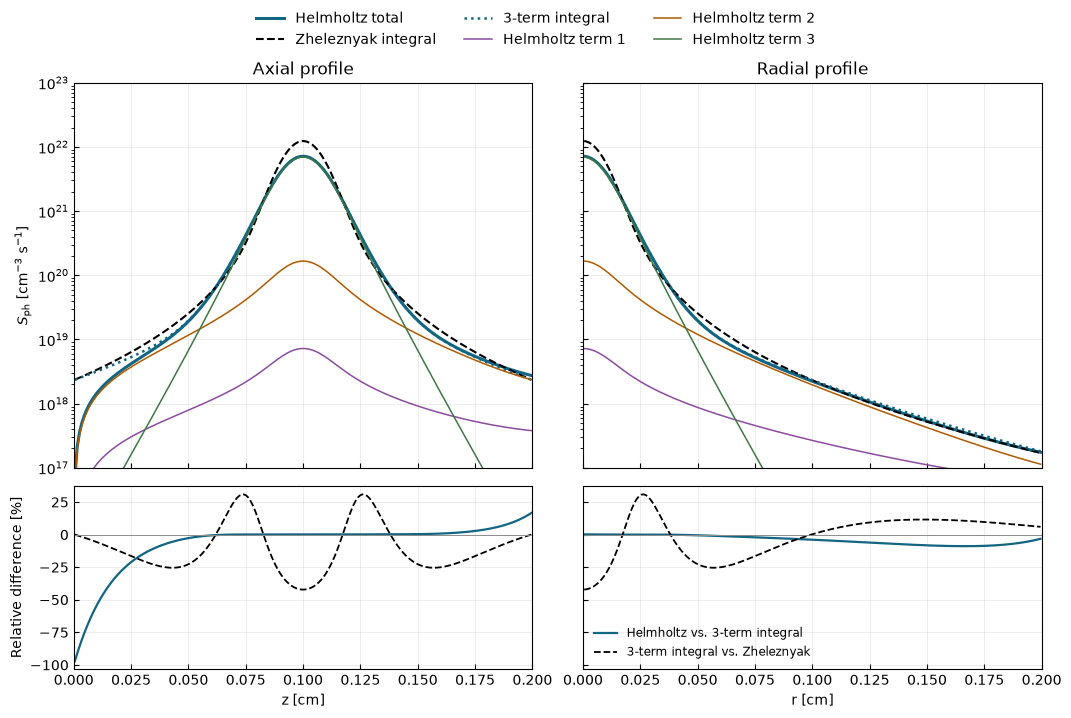

In [4]:
fig, axes = plt.subplots(
    2, 2, figsize=(10.6, 7.1), sharex="col", sharey="row", layout="constrained",
    gridspec_kw={"height_ratios": [2.1, 1]},
)
for col, (name, coordinate, position, _, numerical, parts) in enumerate(cuts):
    x_cm = position * 100
    zheleznyak, free_fit = references[name]
    profile_ax, error_ax = axes[:, col]
    profile_ax.semilogy(x_cm, numerical * 1e-6, color="#126682", lw=2.2, label="Helmholtz total")
    profile_ax.semilogy(x_cm, zheleznyak * 1e-6, "k--", lw=1.5, label="Zheleznyak integral")
    profile_ax.semilogy(x_cm, free_fit * 1e-6, color="#126682", ls=":", lw=1.8,
                        label="3-term integral")
    for term, (part, color) in enumerate(zip(parts, ("#8c4ca0", "#b05b00", "#407845")), start=1):
        profile_ax.semilogy(x_cm, part * 1e-6, color=color, lw=1.1, label=f"Helmholtz term {term}")
    profile_ax.set_title(f"{name} profile")
    profile_ax.set_xlim(0., DOMAIN_M * 100)
    error_ax.plot(x_cm, (numerical / free_fit - 1) * 100, color="#126682", lw=1.6,
                  label="Helmholtz vs. 3-term integral")
    error_ax.plot(x_cm, (free_fit / zheleznyak - 1) * 100, "k--", lw=1.3,
                  label="3-term integral vs. Zheleznyak")
    error_ax.axhline(0., color="0.55", lw=0.7)
    error_ax.set_xlabel(f"{coordinate} [cm]")
    for axis in (profile_ax, error_ax):
        axis.grid(alpha=0.22)
        axis.tick_params(direction="in")
axes[0, 0].set_ylabel(r"$S_{\mathrm{ph}}$ [cm$^{-3}$ s$^{-1}$]")
if RATE_LIMITS_CM is not None:
    axes[0, 0].set_ylim(RATE_LIMITS_CM)
axes[1, 0].set_ylabel("Relative difference [%]")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center",
           ncols=3, frameon=False)
axes[1, 1].legend(loc="best", fontsize=8.5, frameon=False)
plt.show()